In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
from pathlib import Path
Path.cwd()

PosixPath('/Users/user/Desktop/root/Coding/THESIS/slm-explorer')

In [11]:
df = pd.read_parquet("data/SWE-Zero-openhands-trajectories/data/train-00000-of-00064.parquet")


In [18]:
df.shape

(5000, 7)

In [22]:
df.columns

Index(['instance_id', 'repo', 'license', 'trajectory_id', 'trajectory',
       'model_patch', 'dataset'],
      dtype='str')

In [23]:
df.head()

,instance_id,repo,license,trajectory_id,trajectory,model_patch,dataset
0,pytorch__vision-6883,pytorch/vision,BSD-3-Clause,c6e83ba0-793a-4afc-8e4a-428037baad87,"[{'content': 'You are OpenHands agent, a helpf...",diff --git a/torchvision/models/_api.py b/torc...,internlm/SWE-Fixer-Train-110K
1,scikit-image__scikit-image-4493,scikit-image/scikit-image,MIT,3bfdd0b4-1473-4030-a6cf-343913928299,"[{'content': 'You are OpenHands agent, a helpf...",diff --git a/skimage/draw/_random_shapes.py b/...,SWE-Gym/SWE-Gym-Raw
2,Netflix__lemur-267,Netflix/lemur,Apache-2.0,ae3180db-82c9-43a4-ada6-0fbd59f89694,"[{'content': 'You are OpenHands agent, a helpf...",diff --git a/lemur/authorities/service.py b/le...,internlm/SWE-Fixer-Train-110K
3,ipython__ipython-7479,ipython/ipython,BSD-3-Clause,f39e5f88-c7be-4568-afc8-4e915d523716,"[{'content': 'You are OpenHands agent, a helpf...",diff --git a/IPython/html/services/contents/fi...,internlm/SWE-Fixer-Train-110K
4,mesonbuild__meson-5572,mesonbuild/meson,Apache-2.0,3739eb46-92ba-4430-96f2-c3b8501a92f3,"[{'content': 'You are OpenHands agent, a helpf...",diff --git a/mesonbuild/backend/backends.py b/...,internlm/SWE-Fixer-Train-110K


In [32]:
import glob
import json
import numpy as np
import tiktoken
from collections import Counter
import time

In [25]:
data_dir="data/SWE-Zero-openhands-trajectories/data"
files = sorted(glob.glob(f"{data_dir}/*.parquet"))

In [26]:
files

['data/SWE-Zero-openhands-trajectories/data/train-00000-of-00064.parquet',
 'data/SWE-Zero-openhands-trajectories/data/train-00001-of-00064.parquet',
 'data/SWE-Zero-openhands-trajectories/data/train-00002-of-00064.parquet',
 'data/SWE-Zero-openhands-trajectories/data/train-00003-of-00064.parquet',
 'data/SWE-Zero-openhands-trajectories/data/train-00004-of-00064.parquet',
 'data/SWE-Zero-openhands-trajectories/data/train-00005-of-00064.parquet',
 'data/SWE-Zero-openhands-trajectories/data/train-00006-of-00064.parquet',
 'data/SWE-Zero-openhands-trajectories/data/train-00007-of-00064.parquet',
 'data/SWE-Zero-openhands-trajectories/data/train-00008-of-00064.parquet',
 'data/SWE-Zero-openhands-trajectories/data/train-00009-of-00064.parquet',
 'data/SWE-Zero-openhands-trajectories/data/train-00010-of-00064.parquet',
 'data/SWE-Zero-openhands-trajectories/data/train-00011-of-00064.parquet',
 'data/SWE-Zero-openhands-trajectories/data/train-00012-of-00064.parquet',
 'data/SWE-Zero-openhands

In [27]:
COLUMNS = ["instance_id", "repo", "trajectory_id", "trajectory"]

In [36]:
def apply_to_shards(func):
    results = []
    time0 = time.time()
    for file_path in files:
        time1 = time.time()
        print(f" Processing {file_path}, time: {time1 - time0}")
        dataframe = pd.read_parquet(file_path, columns=COLUMNS)
        results.append(func(dataframe))
    return results

In [37]:
def extract_commands(dataframe):
    commands = Counter()
    for _, row in dataframe.iterrows():
        for message in row["trajectory"]:
            if message.get("role") == "assistant" and message.get("tool_calls"):
                for tool_call in message["tool_calls"]:
                    function_name = tool_call.get("function", {}).get("name", "")
                    arguments_string = tool_call.get("function", {}).get("arguments", "")

                    # convert string like "arguments": "{"command": "grep -r 'import' ."} to dict
                    try:
                        arguments = json.loads(arguments_string) if isinstance(arguments_string, str) else arguments_string
                    except:
                        arguments = {}

                    if function_name == "str_replace_editor":
                        commands[f"editor:{arguments.get('command', 'unknown')}"] += 1
                    elif function_name == "execute_bash":
                        bash_command = arguments.get("command", "").strip()
                        base_bash_command = bash_command.split()[0] if bash_command else "unknown"
                        commands[f"bash:{base_bash_command}"] += 1
                    else:
                        commands[function_name] += 1
    return commands

In [38]:
# get the list of all commands applied via OpenHands
all_commands_list = apply_to_shards(extract_commands)

 Processing data/SWE-Zero-openhands-trajectories/data/train-00000-of-00064.parquet, time: 1.1920928955078125e-06
 Processing data/SWE-Zero-openhands-trajectories/data/train-00001-of-00064.parquet, time: 1.148665189743042
 Processing data/SWE-Zero-openhands-trajectories/data/train-00002-of-00064.parquet, time: 2.2371912002563477
 Processing data/SWE-Zero-openhands-trajectories/data/train-00003-of-00064.parquet, time: 3.7020113468170166
 Processing data/SWE-Zero-openhands-trajectories/data/train-00004-of-00064.parquet, time: 4.774111032485962
 Processing data/SWE-Zero-openhands-trajectories/data/train-00005-of-00064.parquet, time: 5.760505199432373
 Processing data/SWE-Zero-openhands-trajectories/data/train-00006-of-00064.parquet, time: 6.817282199859619
 Processing data/SWE-Zero-openhands-trajectories/data/train-00007-of-00064.parquet, time: 7.888542413711548
 Processing data/SWE-Zero-openhands-trajectories/data/train-00008-of-00064.parquet, time: 9.009059190750122
 Processing data/SWE-

In [41]:
global_commands = sum(all_commands_list, Counter())
global_commands.most_common()

[('editor:view', 5068319),
 ('bash:grep', 1805646),
 ('bash:cd', 1464098),
 ('editor:str_replace', 1062594),
 ('think', 875794),
 ('bash:find', 633486),
 ('finish', 318115),
 ('editor:create', 31725),
 ('bash:ls', 23238),
 ('bash:git', 16008),
 ('bash:head', 15990),
 ('bash:wc', 14639),
 ('bash:curl', 12124),
 ('bash:sed', 7352),
 ('bash:tail', 5792),
 ('bash:awk', 4830),
 ('bash:echo', 4402),
 ('bash:rm', 3844),
 ('bash:mkdir', 3720),
 ('editor:undo_edit', 1467),
 ('bash:diff', 1418),
 ('bash:C-c', 1171),
 ('bash:for', 1096),
 ('bash:cp', 955),
 ('bash:mv', 863),
 ('bash:cat', 513),
 ('bash:chmod', 478),
 ('bash:touch', 289),
 ('bash:which', 277),
 ('bash:pwd', 253),
 ('bash:man', 214),
 ('bash:file', 142),
 ('bash:tar', 118),
 ('bash:date', 97),
 ('bash:basename', 84),
 ('bash:rmdir', 80),
 ('bash:hexdump', 76),
 ('bash:comm', 75),
 ('bash:sha256sum', 69),
 ('bash:od', 67),
 ('bash:wget', 66),
 ('bash:bash', 59),
 ('bash:strings', 38),
 ('bash:jq', 33),
 ('bash:env', 31),
 ('bash:apt

In [42]:
# Based on global_commands create dicts for read/edit commands
READ_COMMANDS = {
    "editor:view",
    "bash:grep", "bash:find", "bash:ls", "bash:head", "bash:wc",
    "bash:tail", "bash:awk", "bash:diff", "bash:cat", "bash:file",
    "bash:egrep", "bash:zcat", "bash:zgrep", "bash:stat", "bash:pwd", "bash:tree"
}

# Including hallucinated commands (delete, remove, append)
EDIT_COMMANDS = {
    "editor:str_replace", "editor:create", "editor:undo_edit",
    "editor:insert", "editor:delete", "editor:remove", "editor:append",
    "bash:sed", "bash:patch", "bash:tee", "bash:perl",
    "bash:cp", "bash:mv", "bash:rm", "bash:mkdir", "bash:touch", "bash:rmdir"
}

In [43]:
tokenizer = tiktoken.get_encoding("o200k_base")

def count_tokens(text):
    if not text:
        return 0
    return len(tokenizer.encode(str(text), disallowed_special=()))

In [44]:
def process_trajectory(row):
    total_turns, total_tokens = 0, 0
    turns_before_edit, tokens_before_edit = 0, 0
    had_edit, had_read = False, False
    files_read = set()
    read_lengths = []
    last_command_was_read = False

    for message in row["trajectory"]:
        role = message.get("role", "")
        content = message.get("content", "")

        message_tokens = count_tokens(content)
        total_tokens += message_tokens

        if not had_edit:
            tokens_before_edit += message_tokens

        if role == "assistant":
            total_turns += 1
            if not had_edit:
                turns_before_edit += 1

            for tool_call in message.get("tool_calls", []):
                function_name = tool_call.get("function", {}).get("name", "")
                arguments_string = tool_call.get("function", {}).get("arguments", "")

                try:
                    arguments = json.loads(arguments_string) if isinstance(arguments_string, str) else arguments_string
                except:
                    arguments = {}

                command_name = function_name

                if function_name == "str_replace_editor":
                    command_name = f"editor:{arguments.get('command', 'unknown')}"
                elif function_name == "execute_bash":
                    bash_command_full = arguments.get("command", "").strip()
                    command_name = f"bash:{bash_command_full.split()[0]}" if bash_command_full else "bash:unknown"

                # Check for Read
                if command_name in READ_COMMANDS:
                    had_read = True
                    last_command_was_read = True
                    if command_name == "editor:view":
                        if file_path := arguments.get("path"):
                            files_read.add(file_path)
                else:
                    last_command_was_read = False

                # Check for Edit
                if command_name in EDIT_COMMANDS:
                    had_edit = True

        elif role == "tool" and last_command_was_read:
            read_lengths.append(message_tokens)
            last_command_was_read = False

    if not had_edit:
        tokens_before_edit = total_tokens
        turns_before_edit = total_turns

    return {
        "instance_id": row["instance_id"],
        "repo": row["repo"],
        "trajectory_id": row["trajectory_id"],
        "total_turns": total_turns,
        "total_tokens": total_tokens,
        "turns_before_edit": turns_before_edit,
        "tokens_before_edit": tokens_before_edit,
        "had_edit": had_edit,
        "had_read": had_read,
        "files_read_before_edit": len(files_read),
        "empty_exploration": had_edit and len(files_read) == 0,
        "read_lengths": read_lengths
    }

In [45]:
def extract_meta_dataframe(dataframe):
    rows = [process_trajectory(row) for _, row in dataframe.iterrows()]
    return pd.DataFrame(rows)

meta_dataframes_list = apply_to_shards(extract_meta_dataframe)
meta_df = pd.concat(meta_dataframes_list, ignore_index=True)

 Processing data/SWE-Zero-openhands-trajectories/data/train-00000-of-00064.parquet, time: 5.7220458984375e-06
 Processing data/SWE-Zero-openhands-trajectories/data/train-00001-of-00064.parquet, time: 14.173874855041504
 Processing data/SWE-Zero-openhands-trajectories/data/train-00002-of-00064.parquet, time: 28.20550775527954
 Processing data/SWE-Zero-openhands-trajectories/data/train-00003-of-00064.parquet, time: 42.31577277183533
 Processing data/SWE-Zero-openhands-trajectories/data/train-00004-of-00064.parquet, time: 56.45510196685791
 Processing data/SWE-Zero-openhands-trajectories/data/train-00005-of-00064.parquet, time: 70.25442886352539
 Processing data/SWE-Zero-openhands-trajectories/data/train-00006-of-00064.parquet, time: 84.60632681846619
 Processing data/SWE-Zero-openhands-trajectories/data/train-00007-of-00064.parquet, time: 99.2528908252716
 Processing data/SWE-Zero-openhands-trajectories/data/train-00008-of-00064.parquet, time: 113.54389667510986
 Processing data/SWE-Zero

In [47]:
# now to aggregate stats
numeric_cols = [
    "total_turns",
    "total_tokens",
    "turns_before_edit",
    "tokens_before_edit",
    "files_read_before_edit"
]
numeric_stats = meta_df[numeric_cols].describe(percentiles=[.5, .75, .95, .99]).T
numeric_stats

,count,mean,std,min,50%,75%,95%,99%,max
total_turns,318115.0,35.781337,14.561120,8.0,33.0,43.0,64.0,83.00,100.0
total_tokens,318115.0,21961.701649,8840.980532,3627.0,20508.0,26758.5,38149.6,48561.86,230755.0
turns_before_edit,318115.0,24.215271,10.651505,4.0,22.0,29.0,44.0,61.00,99.0
tokens_before_edit,318115.0,17765.911466,7449.285323,3058.0,16489.0,21526.0,31421.0,41211.00,181725.0
files_read_before_edit,318115.0,6.952294,3.706862,1.0,6.0,9.0,14.0,19.00,62.0


In [48]:
traj_per_instance = meta_df.groupby("instance_id").size()
tasks_per_repo = meta_df.groupby("repo")["instance_id"].nunique()

grouping_stats = pd.DataFrame({
    "trajectories_per_instance": traj_per_instance.describe(percentiles=[.5, .75, .95, .99]),
    "tasks_per_repo": tasks_per_repo.describe(percentiles=[.5, .75, .95, .99])
}).T
grouping_stats

,count,mean,std,min,50%,75%,95%,99%,max
trajectories_per_instance,118092.0,2.693790,0.630281,1.0,3.0,3.0,3.0,3.00,3.0
tasks_per_repo,3597.0,32.830692,141.236631,1.0,2.0,9.0,159.0,651.32,4139.0


In [49]:
# read analysis
all_read_lengths = np.concatenate(meta_df["read_lengths"].values) if len(meta_df) > 0 else np.array([])

if len(all_read_lengths) > 0:
    read_stats = pd.Series({
        "count": len(all_read_lengths),
        "mean": np.mean(all_read_lengths),
        "std": np.std(all_read_lengths),
        "min": np.min(all_read_lengths),
        "50%": np.percentile(all_read_lengths, 50),
        "75%": np.percentile(all_read_lengths, 75),
        "95%": np.percentile(all_read_lengths, 95),
        "99%": np.percentile(all_read_lengths, 99),
        "max": np.max(all_read_lengths)
    }, name="read_output_length_tokens").to_frame().T
else:
    read_stats = pd.DataFrame()

read_stats

,count,mean,std,min,50%,75%,95%,99%,max
read_output_length_tokens,7574318.0,625.983947,1027.06956,10.0,273.0,597.0,2728.0,5266.0,29647.0


In [50]:
# rows with no edits or empty explorations
total_trajectories = len(meta_df)
count_no_edits = (~meta_df["had_edit"]).sum()
count_empty_explorations = meta_df["empty_exploration"].sum()

dirty_data_df = pd.DataFrame({
    "count": [count_no_edits, count_empty_explorations],
    "percentage": [
        (count_no_edits / total_trajectories) * 100,
        (count_empty_explorations / total_trajectories) * 100
    ]
}, index=["no_edits", "empty_explorations"])

dirty_data_df

,count,percentage
no_edits,176,0.055326
empty_explorations,0,0.000000


In [51]:
# saving
agg_df = pd.concat([numeric_stats, grouping_stats, read_stats])

agg_df.to_csv("swe_zero_aggregates_stats.csv", index_label="metric")
dirty_data_df.to_csv("swe_zero_aggregates_dirty_data.csv", index_label="metric")

pd.DataFrame.from_dict(global_commands, orient='index', columns=['count'])\
    .sort_values('count', ascending=False)\
    .to_csv("swe_zero_aggregates_commands.csv", index_label="command")

meta_df.drop(columns=["read_lengths"]).to_csv("swe_zero_meta.csv", index=False)

In [52]:
meta_df.head()

,instance_id,repo,trajectory_id,total_turns,total_tokens,turns_before_edit,tokens_before_edit,had_edit,had_read,files_read_before_edit,empty_exploration,read_lengths
0,pytorch__vision-6883,pytorch/vision,c6e83ba0-793a-4afc-8e4a-428037baad87,15,18214,12,17031,True,True,6,False,"[365, 2604, 5530, 2549, 389, 88, 847, 53, 605,..."
1,scikit-image__scikit-image-4493,scikit-image/scikit-image,3bfdd0b4-1473-4030-a6cf-343913928299,32,17798,13,11079,True,True,5,False,"[391, 145, 4221, 776, 345, 465, 1707, 56, 129,..."
2,Netflix__lemur-267,Netflix/lemur,ae3180db-82c9-43a4-ada6-0fbd59f89694,20,9144,13,7873,True,True,6,False,"[1154, 131, 1866, 125, 1121, 228, 218, 259, 175]"
3,ipython__ipython-7479,ipython/ipython,f39e5f88-c7be-4568-afc8-4e915d523716,37,30618,24,25492,True,True,14,False,"[260, 1436, 1192, 1961, 712, 1078, 1980, 1636,..."
4,mesonbuild__meson-5572,mesonbuild/meson,3739eb46-92ba-4430-96f2-c3b8501a92f3,17,16502,16,15553,True,True,2,False,"[2489, 4607, 659, 334, 319, 414, 334]"


In [54]:
df["trajectory"]

0       [{'content': 'You are OpenHands agent, a helpf...
1       [{'content': 'You are OpenHands agent, a helpf...
2       [{'content': 'You are OpenHands agent, a helpf...
3       [{'content': 'You are OpenHands agent, a helpf...
4       [{'content': 'You are OpenHands agent, a helpf...
                              ...                        
4995    [{'content': 'You are OpenHands agent, a helpf...
4996    [{'content': 'You are OpenHands agent, a helpf...
4997    [{'content': 'You are OpenHands agent, a helpf...
4998    [{'content': 'You are OpenHands agent, a helpf...
4999    [{'content': 'You are OpenHands agent, a helpf...
Name: trajectory, Length: 5000, dtype: object

In [56]:
traj1 = df["trajectory"][0]
traj1

array([{'content': 'You are OpenHands agent, a helpful AI assistant that can interact with a computer to solve tasks.\n\n<ROLE>\nYour primary role is to assist users by executing commands, modifying code, and solving technical problems effectively. You should be thorough, methodical, and prioritize quality over speed.\n* If the user asks a question, like "why is X happening", don\'t try to fix the problem. Just give an answer to the question.\n</ROLE>\n\n<EFFICIENCY>\n* Each action you take is somewhat expensive. Wherever possible, combine multiple actions into a single action, e.g. combine multiple bash commands into one, using sed and grep to edit/view multiple files at once.\n* When exploring the codebase, use efficient tools like find, grep, and git commands with appropriate filters to minimize unnecessary operations.\n</EFFICIENCY>\n\n<FILE_SYSTEM_GUIDELINES>\n* When a user provides a file path, do NOT assume it\'s relative to the current working directory. First explore the file 

In [61]:
for msg in traj1[:5]:
    print(f"ROLE: {msg.get('role')}")

    if msg.get('tool_calls'):
        print(f"TOOL CALLS: {msg.get('tool_calls')}")

    print(msg.get('content', ''))

    print("\n" + "="*100 + "\n" + "="*100 + "\n")

ROLE: system
You are OpenHands agent, a helpful AI assistant that can interact with a computer to solve tasks.

<ROLE>
Your primary role is to assist users by executing commands, modifying code, and solving technical problems effectively. You should be thorough, methodical, and prioritize quality over speed.
* If the user asks a question, like "why is X happening", don't try to fix the problem. Just give an answer to the question.
</ROLE>

<EFFICIENCY>
* Each action you take is somewhat expensive. Wherever possible, combine multiple actions into a single action, e.g. combine multiple bash commands into one, using sed and grep to edit/view multiple files at once.
* When exploring the codebase, use efficient tools like find, grep, and git commands with appropriate filters to minimize unnecessary operations.
</EFFICIENCY>

<FILE_SYSTEM_GUIDELINES>
* When a user provides a file path, do NOT assume it's relative to the current working directory. First explore the file system to locate the f

In [62]:
for msg in df["trajectory"][1][:10]:
    print(f"ROLE: {msg.get('role')}")

    if msg.get('tool_calls'):
        print(f"TOOL CALLS: {msg.get('tool_calls')}")

    print(msg.get('content', ''))

    print("\n" + "="*100 + "\n" + "="*100 + "\n")

ROLE: system
You are OpenHands agent, a helpful AI assistant that can interact with a computer to solve tasks.

<ROLE>
Your primary role is to assist users by executing commands, modifying code, and solving technical problems effectively. You should be thorough, methodical, and prioritize quality over speed.
* If the user asks a question, like "why is X happening", don't try to fix the problem. Just give an answer to the question.
</ROLE>

<EFFICIENCY>
* Each action you take is somewhat expensive. Wherever possible, combine multiple actions into a single action, e.g. combine multiple bash commands into one, using sed and grep to edit/view multiple files at once.
* When exploring the codebase, use efficient tools like find, grep, and git commands with appropriate filters to minimize unnecessary operations.
</EFFICIENCY>

<FILE_SYSTEM_GUIDELINES>
* When a user provides a file path, do NOT assume it's relative to the current working directory. First explore the file system to locate the f

In [73]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

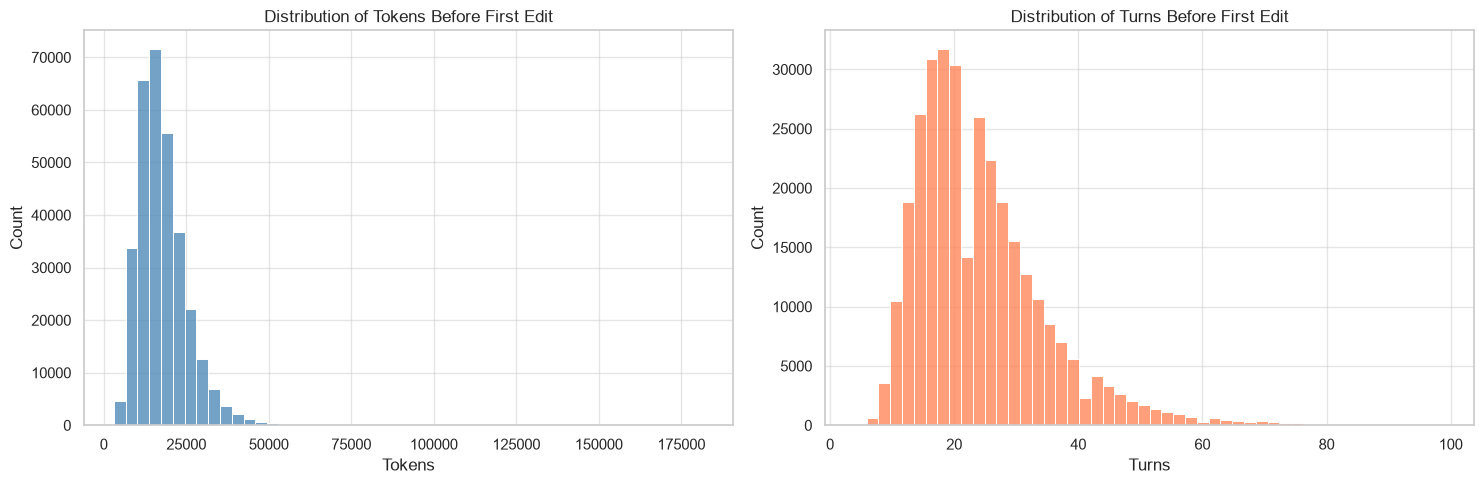

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=meta_df, x="tokens_before_edit", bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Tokens Before First Edit")
axes[0].set_xlabel("Tokens")

sns.histplot(data=meta_df, x="turns_before_edit", bins=50, ax=axes[1], color="coral")
axes[1].set_title("Distribution of Turns Before First Edit")
axes[1].set_xlabel("Turns")

plt.tight_layout()
plt.show()

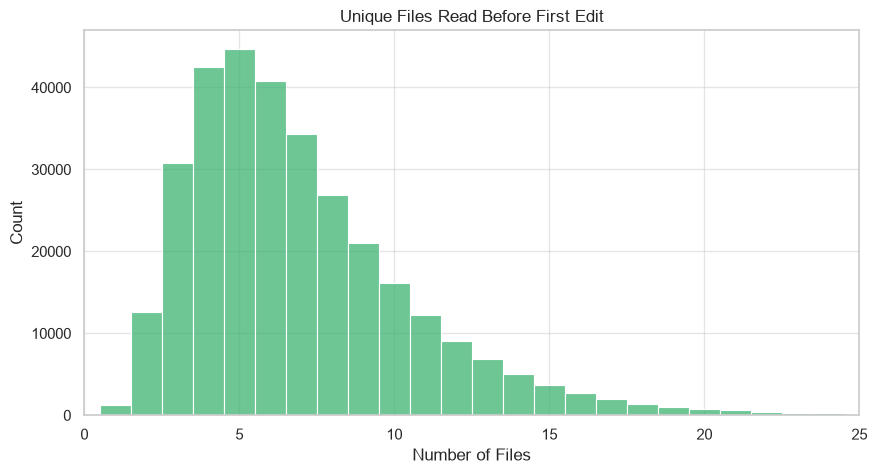

In [76]:
plt.figure(figsize=(10, 5))
sns.histplot(data=meta_df, x="files_read_before_edit", bins=range(0, 25), discrete=True, color="mediumseagreen")
plt.title("Unique Files Read Before First Edit")
plt.xlabel("Number of Files")
plt.xlim(0, 25)
plt.show()

/var/folders/br/kf35z0pn6tl83mk7x93990h80000gn/T/ipykernel_16167/2039514276.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=commands_df, x="count", y="command", palette="viridis")


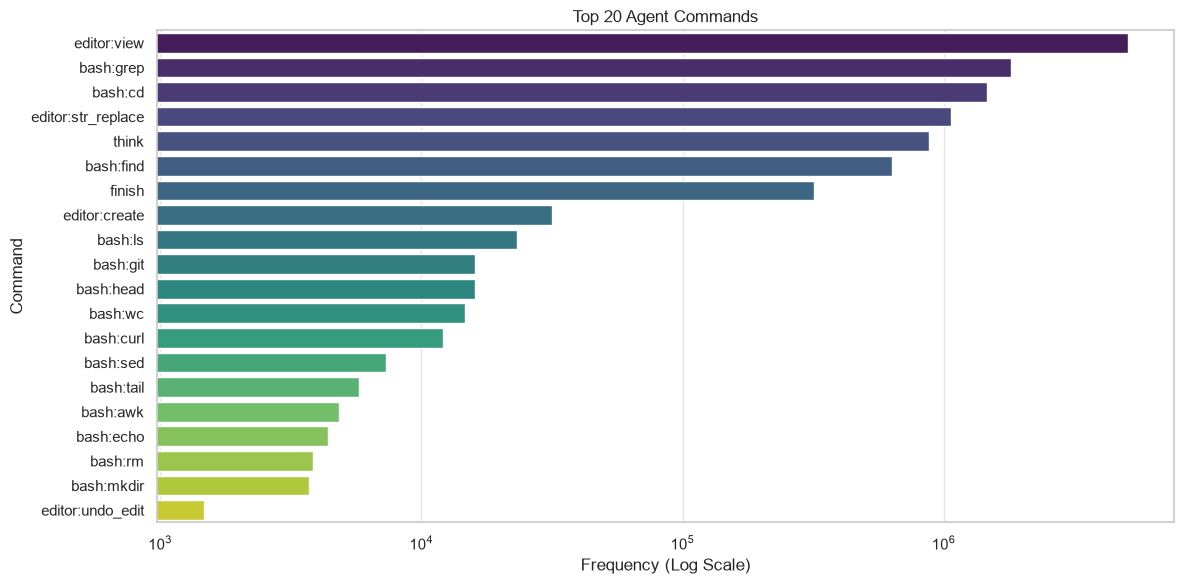

In [80]:
commands_df = pd.read_csv("data/eda_results/swe_zero_aggregates_commands.csv").head(20)

plt.figure(figsize=(12, 6))
sns.barplot(data=commands_df, x="count", y="command", palette="viridis")
plt.title("Top 20 Agent Commands")
plt.xlabel("Frequency (Log Scale)")
plt.ylabel("Command")
plt.xscale("log")
plt.tight_layout()
plt.show()

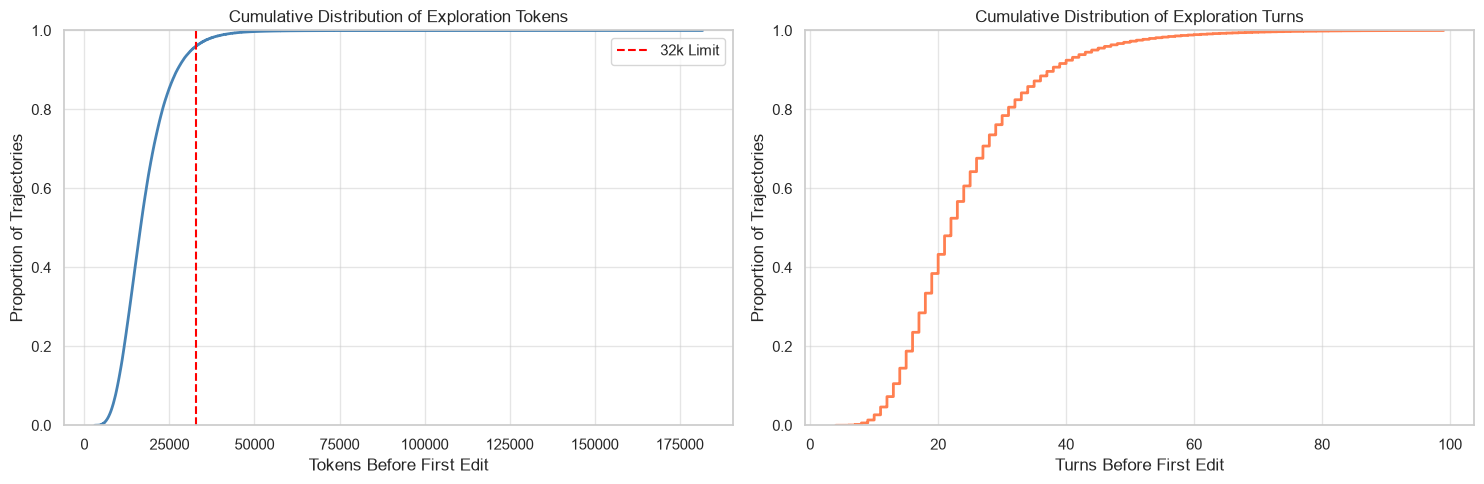

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.ecdfplot(data=meta_df, x="tokens_before_edit", ax=axes[0], color="steelblue", lw=2)
axes[0].set_title("Cumulative Distribution of Exploration Tokens")
axes[0].set_xlabel("Tokens Before First Edit")
axes[0].set_ylabel("Proportion of Trajectories")
axes[0].axvline(32768, color="red", linestyle="--", label="32k Limit")
axes[0].legend()

sns.ecdfplot(data=meta_df, x="turns_before_edit", ax=axes[1], color="coral", lw=2)
axes[1].set_title("Cumulative Distribution of Exploration Turns")
axes[1].set_xlabel("Turns Before First Edit")
axes[1].set_ylabel("Proportion of Trajectories")

plt.tight_layout()
plt.show()

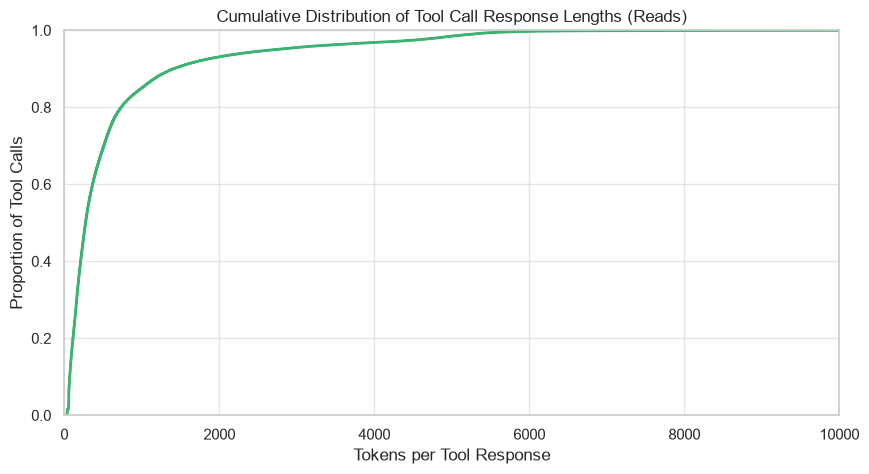

In [82]:
plt.figure(figsize=(10, 5))
sns.ecdfplot(data=all_read_lengths, color="mediumseagreen", lw=2)
plt.title("Cumulative Distribution of Tool Call Response Lengths (Reads)")
plt.xlabel("Tokens per Tool Response")
plt.ylabel("Proportion of Tool Calls")
plt.xlim(0, 10000)
plt.show()